# 04 — Cost-Aware Momentum Backtest: Step-by-Step Lab

This notebook is the **experimental, unpacked version of `backtest.py`**. Read and execute it from top to bottom to see every intermediate calculation. The backtest is calculated in cells; `run_backtest()` is called **only at the end** to check agreement.

The calculation follows this sequence:

**Raw decile returns → WML → rolling risk → month-end forecast → lagged exposure → common sample → turnover proxy → costs → net returns → wealth and metrics.**

We reuse data cleaning and performance reporting from the existing package. Risk estimation, weight timing and cost accounting are written out explicitly here. Notebook 02 remains the gross-return paper replication; this notebook adds an illustrative cost scenario without changing that work.

All returns and cost deductions are decimals: `0.01 = 1%`. The default scenario below is historical and in-sample, not a claim of executable net alpha.

**Exploration only:** The unpacked accounting is pedagogical and verifies the engine. Official factor-proxy reports are generated by `pipeline.baseline_reports` into the configured results tree; the notebook does not export reported results. Stock costs remain separate in Notebook 05.

## 1. Environment and adjustable parameters

Run with the repository's `.venv` kernel. This cell finds the project whether the notebook is launched from the repository root or `notebooks/`. No data downloads, cache writes or research-file overwrites occur.

The 10 bps trading fee and 100 bps annual financing spread are **illustrative assumptions**, not requirements from the paper. Set both to zero to recover gross returns. A basis point is `0.0001`; the financing spread is annual, while returns here are monthly.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
from momentum_risk_project.paths import project_root
from momentum_risk_project.config import load_config, configured_path, config_digest

ROOT = project_root()
CONFIG = load_config(root=ROOT)
RESULTS = configured_path(CONFIG, "results", ROOT)
STUDY = configured_path(CONFIG, "study", ROOT)
BUILD_PATH = configured_path(CONFIG, "build", ROOT)
HIST = RESULTS / "replication/tables/paper_available_common"
if not (HIST / "run.json").exists():
    raise FileNotFoundError("Generate official results first: python run_all.py")
assert __import__("json").loads((HIST / "run.json").read_text())["config_digest"] == config_digest(CONFIG)

import matplotlib.pyplot as plt
from momentum_risk_project.data import clean_momentum
from momentum_risk_project.metrics import performance_metrics
TRANSACTION_COST_BPS=CONFIG["costs"]["baseline_bps"]
FINANCING_COST_BPS=CONFIG["costs"]["lab_financing_cost_bps"]
TARGET_VOLATILITY=CONFIG["risk"]["annual_target"]
LEVERAGE_CAP=None
WINDOW=CONFIG["risk"]["window"]
TRADING_DAYS_PER_MONTH=CONFIG["risk"]["trading_days_per_month"]
START,END=CONFIG["windows"]["paper_available_common"]


## 2. Load the same decile inputs as Notebook 02

Use the existing raw value-weighted ten-decile Parquets. `clean_momentum()` selects the highest and lowest deciles and converts percent returns to decimals:

$$r^{WML}_t=(r^{P10}_t-r^{P1}_t)/100.$$

Daily WML estimates risk; the independently published monthly WML supplies holding-period returns. Do not compound daily long-short spreads to manufacture monthly WML. Do not substitute the old `01_momentum_*` caches or the distinct 2×3 `Mom` factor.

The unusual nested cache location below reflects the existing local repository. Change these two paths if you move the caches; missing inputs raise an error rather than triggering downloads.

In [2]:
RAW_DIR = ROOT / "data/raw"
DAILY_PATH = configured_path(CONFIG,"kf_daily",ROOT)
MONTHLY_PATH = configured_path(CONFIG,"kf_monthly",ROOT)
for path in (DAILY_PATH, MONTHLY_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Existing Notebook 02 input required: {path}")

daily = clean_momentum(pd.read_parquet(DAILY_PATH), "daily")["mom"]
monthly = clean_momentum(pd.read_parquet(MONTHLY_PATH), "monthly")["mom"]
assert monthly.index.equals(pd.period_range(monthly.index[0], monthly.index[-1], freq="M"))
print(f"Daily input: {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"Monthly input: {monthly.index[0]} to {monthly.index[-1]}")
display(monthly.head().to_frame("monthly_wml"))

Daily input: 1926-11-03 to 2026-08-31
Monthly input: 1927-01 to 2026-08


,monthly_wml
month,
1927-01,0.0308
1927-02,-0.0035
1927-03,0.0873
1927-04,0.0421
1927-05,0.0328


## 3. Estimate risk using the last 126 trading observations

At each trading date, take the mean of squared daily WML returns, multiply by 21 and take the square root:

$$\widehat\sigma_d=\sqrt{\frac{21}{126}\sum_{j=0}^{125}(r^{WML}_{d-j})^2}.$$

This is a squared-return estimator, **not demeaned sample standard deviation**. Its output is already in monthly units. The current day's observation is included; the first 125 estimates are missing. At this stage there is no shift.

Keep all available daily history before selecting the investment interval: otherwise the evaluation start date would unnecessarily restart the risk warm-up.

In [3]:
daily_sigma = np.sqrt(
    TRADING_DAYS_PER_MONTH
    * daily.pow(2).rolling(window=WINDOW, min_periods=WINDOW).mean()
).rename("historical_volatility")

# Take the actual last observed estimate, preserving a missing final estimate.
# A groupby.last() could skip NaN values; this explicit selection does not.
monthly_sigma = daily_sigma.groupby(daily_sigma.index.to_period("M")).agg(
    lambda values: values.iloc[-1]
)
display(pd.concat([daily.rename("daily_wml"), daily_sigma], axis=1).iloc[WINDOW-3:WINDOW+2])
display(monthly_sigma.head(8).to_frame("monthly_sigma"))

,daily_wml,historical_volatility
date,,
1927-04-01,-0.0009,NaN
1927-04-02,-0.0118,NaN
1927-04-04,0.0103,0.053771
1927-04-05,0.0272,0.054608
1927-04-06,-0.0147,0.054927


,monthly_sigma
date,
1926-11,NaN
1926-12,NaN
1927-01,NaN
1927-02,NaN
1927-03,NaN
1927-04,0.053473
1927-05,0.051880
1927-06,0.050227


## 4. Turn month-end risk into next month's applied exposure

The annualized target becomes `TARGET_VOLATILITY / sqrt(12)` in monthly units:

$$w_t=\frac{0.12/\sqrt{12}}{\widehat\sigma_{t-1}}.$$

For a holding month `t`, the denominator comes from the **previous** month-end. Shift once, after month-end risk alignment. Shifting daily risk as well would introduce an extra lag. Current-month WML is multiplied by this already chosen exposure.

A unit of WML means a +1 winner leg and a −1 loser leg. Thus `w = 1` has 2 units of gross leg notional. A cap limits factor exposure, not total gross leg notional.

In [4]:
aligned_sigma = monthly_sigma.reindex(monthly.index)
assert not np.isinf(aligned_sigma.to_numpy()).any()
assert (aligned_sigma.dropna() > 0).all()
monthly_target = TARGET_VOLATILITY / np.sqrt(12)
month_end_weight = monthly_target / aligned_sigma
applied_weight = month_end_weight.shift(1)
if LEVERAGE_CAP is not None:
    applied_weight = applied_weight.clip(upper=LEVERAGE_CAP)

timing = pd.DataFrame({
    "wml_current_month": monthly,
    "sigma_current_month_end": aligned_sigma,
    "sigma_previous_month_end": aligned_sigma.shift(1),
    "applied_weight": applied_weight,
    "managed_gross_return": applied_weight * monthly,
})
display(timing.loc["1927-03":"1927-08"])

# The inspected month's weight must use the preceding calendar month's risk.
example_month = applied_weight.first_valid_index()
expected_weight = monthly_target / aligned_sigma.loc[example_month - 1]
if LEVERAGE_CAP is not None:
    expected_weight = min(expected_weight, LEVERAGE_CAP)
assert np.isclose(applied_weight.loc[example_month], expected_weight)

,wml_current_month,sigma_current_month_end,sigma_previous_month_end,applied_weight,managed_gross_return
month,,,,,
1927-03,0.0873,NaN,NaN,NaN,NaN
1927-04,0.0421,0.053473,NaN,NaN,NaN
1927-05,0.0328,0.051880,0.053473,0.647827,0.021249
1927-06,0.0436,0.050227,0.051880,0.667718,0.029113
1927-07,0.0893,0.046393,0.050227,0.689684,0.061589
1927-08,0.0611,0.045694,0.046393,0.746683,0.045622


## 5. Select a common investment episode

Drop only leading risk warm-up, then apply `START` and `END`. An unavailable forecast inside the selected episode raises an error; the backtest does not silently skip that month or carry stale risk forward.

Both unmanaged and managed strategies use exactly these months. Each episode starts from cash (previous factor exposure zero). Moving `START` therefore creates a new initial entry fee; it is not a slice of an already invested account. As in the current engine, lagged weights are constructed on the supplied monthly-return index, so its first month has no applied weight.

In [5]:
valid_weights = applied_weight.dropna()
if valid_weights.empty:
    raise ValueError("No investable months after risk warm-up")
selected_weight = applied_weight.loc[valid_weights.index[0]:].loc[START:END]
if selected_weight.isna().any():
    raise ValueError("Missing lagged risk within the investment episode")
if len(selected_weight) < 2:
    raise ValueError("At least two investable months are required")

wml = monthly.reindex(selected_weight.index).rename("unmanaged")
weights = pd.DataFrame({"unmanaged": 1.0, "managed": selected_weight})
print(f"Common sample: {weights.index[0]} to {weights.index[-1]} ({len(weights):,} months)")
display(weights.head())

Common sample: 1927-07 to 2011-12 (1,014 months)


,unmanaged,managed
month,,
1927-07,1.0,0.689684
1927-08,1.0,0.746683
1927-09,1.0,0.758114
1927-10,1.0,0.791401
1927-11,1.0,0.730455


## 6. Inspect the traded-notional proxy before charging costs

For the idealized factor legs `(+w, −w)`, changing exposure trades both sides:

$$T_t=|w_t-w_{t-1}|+|-w_t-(-w_{t-1})|=2|w_t-w_{t-1}|.$$

This is **total traded notional divided by the assumed capital base**, not a half-turnover convention. Examples:

- Entering from 0 to 1 trades 1 long plus 1 short: proxy = 2.
- Moving from 1 to 1.2 trades 0.2 on each leg: proxy = 0.4.
- Staying at 1.2 gives zero in this proxy, even though the underlying stocks may trade.

At 10 bps per dollar traded, the initial 1x entry costs `2 × 10 / 10,000 = 0.002`, or 0.2% of capital. There is no terminal liquidation charge in the current MVP.

In [6]:
toy_weight = pd.Series([1.0, 1.2, 1.2], name="weight")
toy_previous = toy_weight.shift(1, fill_value=0.0)
toy = pd.DataFrame({"previous_weight": toy_previous, "weight": toy_weight})
toy["turnover_proxy"] = 2 * (toy_weight - toy_previous).abs()
toy["transaction_cost_at_10bps"] = toy["turnover_proxy"] * 10 / 10000
display(toy)

previous_weights = weights.shift(1, fill_value=0.0)
turnover_proxy = 2 * (weights - previous_weights).abs()
display(turnover_proxy.head())

,previous_weight,weight,turnover_proxy,transaction_cost_at_10bps
0,0.0,1.0,2.0,0.0020
1,1.0,1.2,0.4,0.0004
2,1.2,1.2,0.0,0.0000


,unmanaged,managed
month,,
1927-07,2.0,1.379367
1927-08,0.0,0.113998
1927-09,0.0,0.022862
1927-10,0.0,0.066575
1927-11,0.0,0.121893


## 7. Calculate gross returns, trading fees and optional financing

For each strategy and holding month:

$$R^{gross}_t=w_t r^{WML}_t,$$
$$C^{trade}_t=T_t\,\frac{\text{transaction\_cost\_bps}}{10,000},$$
$$C^{finance}_t=\max(|w_t|-1,0)\,\frac{\text{financing\_cost\_bps}}{10,000\times12},$$
$$R^{net}_t=R^{gross}_t-C^{trade}_t-C^{finance}_t.$$

All cost columns are positive deductions in units of monthly capital return. Financing is a simple annual spread divided by 12, charged only on factor exposure above 1. This is an explicit scenario convention; it does not calculate broker margin, short borrow fees or rebates. Setting it to zero disables the charge.

Notice that unmanaged exposure stays at 1. Under this proxy it pays only the initial trading fee and no financing spread. This understates its real ongoing implementation cost.

In [7]:
gross_returns = weights.mul(wml, axis=0)
transaction_costs = turnover_proxy * TRANSACTION_COST_BPS / 10000
financing_costs = (
    (weights.abs() - 1).clip(lower=0) * FINANCING_COST_BPS / 10000 / 12
)
net_returns = gross_returns - transaction_costs - financing_costs

frames = []
for strategy in weights.columns:
    frame = pd.DataFrame({
        "weight": weights[strategy],
        "wml": wml,
        "turnover_proxy": turnover_proxy[strategy],
        "transaction_cost": transaction_costs[strategy],
        "financing_cost": financing_costs[strategy],
        "gross_return": gross_returns[strategy],
        "net_return": net_returns[strategy],
    })
    frames.append(frame)

# Read across one row: exposure -> traded notional -> fees -> gross/net return.
display(frames[1].head().style.format("{:.6f}"))
np.testing.assert_allclose(
    frames[1]["gross_return"] - frames[1]["net_return"],
    frames[1]["transaction_cost"] + frames[1]["financing_cost"],
    atol=1e-14,
)

,weight,wml,turnover_proxy,transaction_cost,financing_cost,gross_return,net_return
month,,,,,,,
1927-07,0.689684,0.089300,1.379367,0.001379,0.000000,0.061589,0.060209
1927-08,0.746683,0.061100,0.113998,0.000114,0.000000,0.045622,0.045508
1927-09,0.758114,0.076800,0.022862,0.000023,0.000000,0.058223,0.058200
1927-10,0.791401,0.000200,0.066575,0.000067,0.000000,0.000158,0.000092
1927-11,0.730455,-0.074300,0.121893,0.000122,0.000000,-0.054273,-0.054395


## 8. Compound returns and summarize performance

For an initial capital of 1, wealth is $V_t=\prod_{s\le t}(1+R_s)$. Gross and net wealth each reinvest their own returns. Annualized arithmetic mean is `12 × monthly mean`; annualized volatility is `sqrt(12) × sample standard deviation`. Sharpe here uses a zero risk-free rate. CAGR measures compounded growth and is different from arithmetic mean.

The existing `metrics.py` also reports maximum drawdown against a running peak that includes initial capital 1. If a return is at or below −100%, the ordinary wealth interpretation breaks down: the engine marks the entire corresponding wealth column and wealth-based metrics as missing. It does not simulate liquidation.

In [8]:
summaries = {}
for strategy, frame in zip(weights.columns, frames):
    for kind in ("gross", "net"):
        returns = frame[f"{kind}_return"]
        frame[f"{kind}_wealth"] = (
            (1 + returns).cumprod() if (returns > -1).all() else np.nan
        )
        summaries[f"{strategy}_{kind}"] = performance_metrics(returns)

ledger = pd.concat(frames, keys=list(weights.columns), names=["strategy", "month"])
summary = pd.DataFrame(summaries).T
display(summary.style.format("{:.6f}"))

# Annualized mean cost drag is an arithmetic decomposition, not a CAGR difference.
cost_diagnostics = pd.DataFrame({
    "mean_monthly_turnover_proxy": turnover_proxy.mean(),
    "annualized_trading_drag": transaction_costs.mean() * 12,
    "annualized_financing_drag": financing_costs.mean() * 12,
    "annualized_total_mean_drag": (gross_returns - net_returns).mean() * 12,
})
display(cost_diagnostics.style.format("{:.6f}"))

,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Terminal Wealth
unmanaged_gross,0.147986,0.274467,0.539175,0.105789,-0.955552,4901.367359
unmanaged_net,0.147962,0.274460,0.539102,0.105765,-0.955552,4892.368245
managed_gross,0.166682,0.167807,0.993299,0.163712,-0.438301,366393.213932
managed_net,0.163904,0.167684,0.977457,0.160542,-0.438782,290972.748017


,mean_monthly_turnover_proxy,annualized_trading_drag,annualized_financing_drag,annualized_total_mean_drag
unmanaged,0.001972,0.000024,0.000000,0.000024
managed,0.133564,0.001603,0.001175,0.002778


## 9. Visual checks

The first panel shows reinvested wealth on a logarithmic scale; it is not an estimate of trading capacity. The second panel makes exposure changes visible. The third panel shows the two managed-strategy cost components as monthly deductions. A smooth unmanaged cost path after entry reflects the proxy's missing constituent turnover.

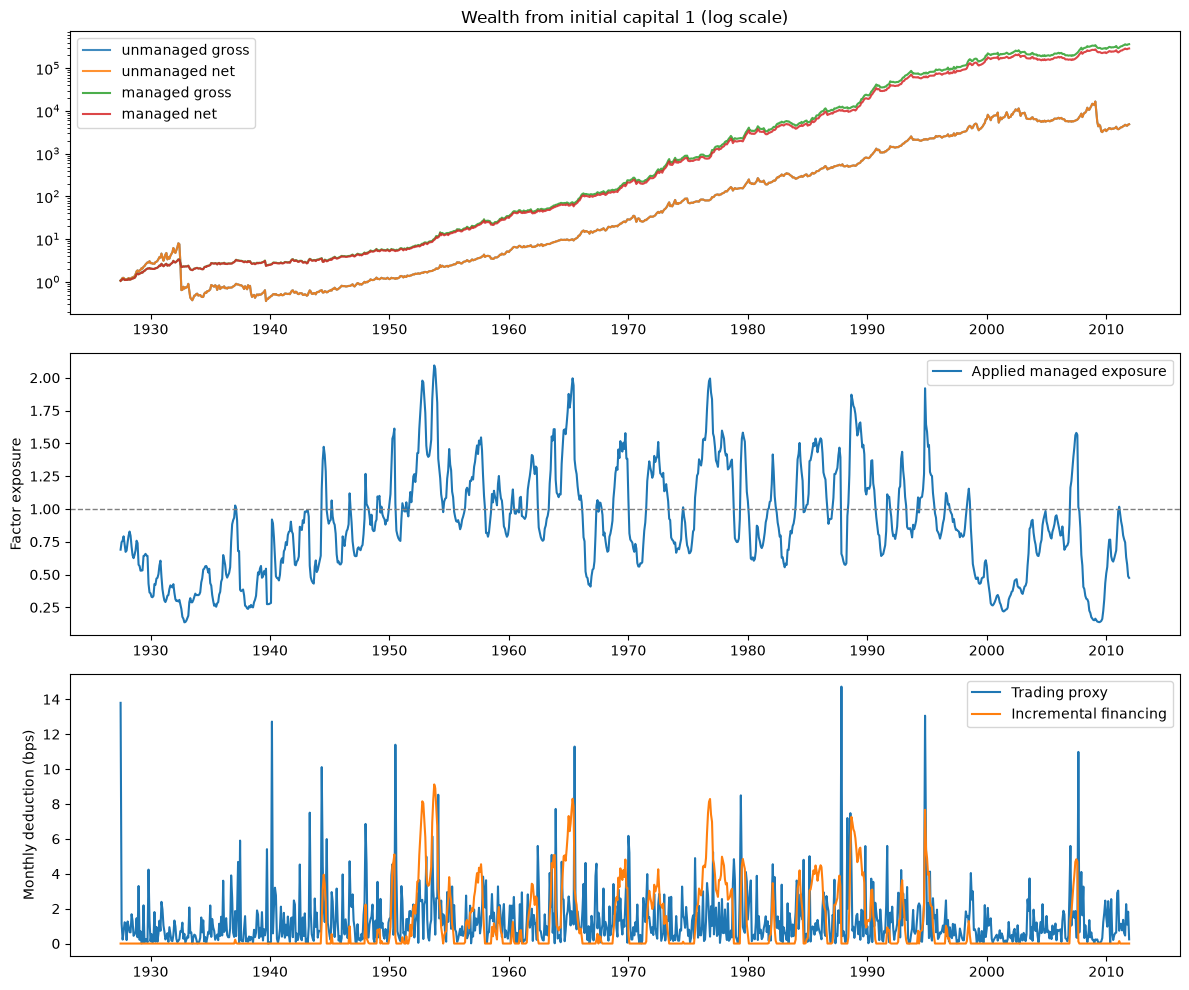

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for strategy in weights.columns:
    strategy_ledger = ledger.loc[strategy]
    for kind in ("gross", "net"):
        axes[0].plot(strategy_ledger.index.to_timestamp(), strategy_ledger[f"{kind}_wealth"],
                     label=f"{strategy} {kind}", alpha=0.85)
axes[0].set_yscale("log")
axes[0].set_title("Wealth from initial capital 1 (log scale)")
axes[0].legend()
axes[1].plot(weights.index.to_timestamp(), weights["managed"], label="Applied managed exposure")
axes[1].axhline(1, color="gray", linestyle="--", linewidth=1)
axes[1].set_ylabel("Factor exposure")
axes[1].legend()
axes[2].plot(transaction_costs.index.to_timestamp(), transaction_costs["managed"] * 10000,
             label="Trading proxy")
axes[2].plot(financing_costs.index.to_timestamp(), financing_costs["managed"] * 10000,
             label="Incremental financing")
axes[2].set_ylabel("Monthly deduction (bps)")
axes[2].legend()
fig.tight_layout()
plt.show()

## 10. Verify the unpacked calculation against the package

Only now call the reusable implementation. Compare the **entire monthly ledger** and all performance metrics, not just a rounded headline number. Also compare the explicit risk and lagged-weight steps against their reusable modules.

If you change the experimental accounting conventions above, an assertion failure here can be useful: it tells you where the experiment has intentionally diverged from the current engine. Make a deliberate decision before porting that change into production code.

In [10]:
from momentum_risk_project.backtest import run_backtest
from momentum_risk_project.volatility import historical_volatility
from momentum_risk_project.strategies import volatility_managed_momentum

pd.testing.assert_series_equal(
    daily_sigma, historical_volatility(daily, window=WINDOW)
)
reference_strategy = volatility_managed_momentum(monthly, monthly_sigma, TARGET_VOLATILITY)
reference_weight = reference_strategy["weight"]
if LEVERAGE_CAP is not None:
    reference_weight = reference_weight.clip(upper=LEVERAGE_CAP)
pd.testing.assert_series_equal(applied_weight, reference_weight, check_names=False)

reference_ledger, reference_summary = run_backtest(
    daily, monthly,
    transaction_cost_bps=TRANSACTION_COST_BPS,
    financing_cost_bps=FINANCING_COST_BPS,
    target_volatility=TARGET_VOLATILITY,
    leverage_cap=LEVERAGE_CAP,
    window=WINDOW,
    start=START,
    end=END,
)
pd.testing.assert_frame_equal(ledger, reference_ledger)
pd.testing.assert_frame_equal(summary, reference_summary)
print("PASS: explicit notebook calculations match the full engine ledger and summary.")

PASS: explicit notebook calculations match the full engine ledger and summary.


## 11. Experiments to try and interpretation limits

Change parameters in Section 1 and **rerun all cells** so displayed intermediate values stay consistent.

1. Set both costs to zero. Gross and net return columns should coincide.
2. Set financing to zero while keeping trading at 10 bps. Inspect trading-only drag.
3. Try 25 or 50 bps trading costs and inspect the net Sharpe and drawdown.
4. Set `LEVERAGE_CAP = 2.0`. Inspect which weights and cost months change.
5. Change `START` to `1964-01`. Risk still uses earlier daily history, but entry starts from zero again.

**What this experiment cannot answer:** actual constituent turnover is not observable from a WML return series. Constant factor exposure still requires stock-level reconstitution and drift rebalancing. The proxy also omits market impact, time-varying spreads, stock borrow costs, cash yield, margin constraints and forced liquidation. A 1x factor already has 2x gross leg notional, so the optional financing formula is not a complete funding model.

These limitations especially understate unmanaged costs. Use security-level holdings and pre-trade drift-adjusted weights for a tradable turnover model. Keep this experimental notebook separate from Notebook 02's gross paper replication and Notebook 03's stock-level research.

This notebook intentionally saves no external files. Its executed outputs are stored inside this new `.ipynb`; the CLI remains the reproducible export path described in `BACKTEST.md`.

## 12. Packaged API quick start

`momentum_risk_project.backtest.run_backtest(daily_returns, monthly_returns, ...)` reproduces the full factor-level ledger calculated above. Both inputs are decimal WML Series with unique sorted date indexes: daily `DatetimeIndex`, monthly consecutive `PeriodIndex`. Supply full earlier daily history for warm-up; `start` and `end` select the investment episode after risk estimation.

Adjust `transaction_cost_bps`, `financing_cost_bps`, `target_volatility`, `leverage_cap`, `window`, `start` and `end`. The target is annualized; the financing spread is an annual bps scenario. Each selected episode starts with zero prior exposure and pays its own entry fee. Risk estimation and the monthly execution lag happen inside the engine: **do not pre-shift the inputs**.

The function returns `(ledger, summary)`. `ledger` has a `(strategy, month)` index and weights, WML, turnover proxy, fees, gross/net returns and wealth. `summary` contains unmanaged/managed gross/net performance metrics. The example reuses this notebook's settings, including its illustrative financing spread, and checks the full outputs rather than only rounded metrics. This remains a factor-scaling cost proxy; for constituent costs call the Notebook 05 stock-account API.


In [11]:
from momentum_risk_project.backtest import run_backtest

api_ledger, api_summary = run_backtest(
    daily_returns=daily,
    monthly_returns=monthly,
    transaction_cost_bps=TRANSACTION_COST_BPS,
    financing_cost_bps=FINANCING_COST_BPS,
    target_volatility=TARGET_VOLATILITY,
    leverage_cap=LEVERAGE_CAP,
    window=WINDOW,
    start=START,
    end=END,
)
pd.testing.assert_frame_equal(api_ledger, ledger)
pd.testing.assert_frame_equal(api_summary, summary)
print("Packaged factor-proxy ledger and performance summary match the unpacked calculation.")
display(api_summary)

api_report=pd.read_csv(HIST/"factor_proxy_summary.csv",index_col=0)
pd.testing.assert_frame_equal(api_summary,api_report,atol=1e-12)
print("Teaching derivation and engine also match the standalone scripted factor-proxy report.")


Packaged factor-proxy ledger and performance summary match the unpacked calculation.


,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Terminal Wealth
unmanaged_gross,0.147986,0.274467,0.539175,0.105789,-0.955552,4901.367359
unmanaged_net,0.147962,0.274460,0.539102,0.105765,-0.955552,4892.368245
managed_gross,0.166682,0.167807,0.993299,0.163712,-0.438301,366393.213932
managed_net,0.163904,0.167684,0.977457,0.160542,-0.438782,290972.748017


Teaching derivation and engine also match the standalone scripted factor-proxy report.


**CLI equivalent:** run `uv run python -m momentum_risk_project.cli --help` from the repository root. For this notebook's raw decile snapshots, a matching export is:

```bash
uv run python -m momentum_risk_project.cli \
  --daily data/raw/02_kf_momentum_deciles_daily_vw.parquet \
  --monthly data/raw/02_kf_momentum_deciles_monthly_vw.parquet \
  --raw-deciles --transaction-cost-bps 10 --financing-cost-bps 100 \
  --target-volatility 0.12 --window 126 --start 1927-07 --end 2011-12 \
  --output-dir results/factor_proxy_cli_new
```

Choose a new output directory: this CLI refuses to overwrite an existing one. Adjust parameters to match any changes made to the notebook settings. Financing 100bp is the lab scenario, not Notebook 05's zero-financing baseline.

## Package tests and notebook validation

Run these commands **in a terminal from the repository root**, using the project environment. The focused suite covers factor-proxy accounting, timing, risk and metrics; CLI integration is covered in test_backtest.py:

```bash
uv run pytest -p no:cacheprovider tests/test_backtest.py tests/test_volatility.py tests/test_strategies.py tests/test_metrics.py -q
```

Run the complete existing suite before integration:

```bash
uv run pytest -p no:cacheprovider tests/ -q
uv run pytest tests/test_risk_inputs.py -q
uv run pytest tests/test_pipeline.py -q
```

Unit tests use synthetic/local fixtures and do not require WRDS credentials or live market-data downloads. They validate implementation behavior; they do not establish equivalence to a particular CRSP/KF vintage or resolve missing economic payoffs. The executed API examples above additionally validate the shown notebook/data comparisons and require their documented local inputs. These checks are distinct from executing the entire notebook on the full research sample. If parameters, source inputs or valuation conventions change, rerun the relevant notebook and its comparisons as well as the tests. Planned EWMA/GARCH files and tests are not part of these implemented commands.